# 53장 · SQL SELECT·JOIN·GROUP BY

SQL에서는 WHERE로 행을 고르고, JOIN으로 표를 연결하고, GROUP BY로 그룹별 값을 집계합니다.

도서관 질문을 남긴 사람이 누구인지 보려는데 질문 표에는 alice라는 ID만 있습니다. 사용자 표에서 같은 ID를 찾아 이름을 붙이는 작업부터 시작합니다. 수업용 가상 데이터만 사용합니다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.


## WHERE와 ORDER BY로 최근 행 조회

관계형 데이터베이스는 같은 종류의 기록을 표에 저장합니다. course_users에는 사용자 한 명당 한 행, course_turns에는 질문 한 건당 한 행이 있습니다. 작은 예제는 같은 이름의 두 표를 SQLite 메모리에 만들고 SQL의 결과부터 관찰합니다. 강사가 준비한 PostgreSQL의 실제 테이블을 읽는 셀은 마지막에 있습니다.


### 셀 01 · SQLite 테이블과 테스트 데이터

수업용 원자료에서 가져온 질문 세 건을 넣고 alice의 질문만 읽습니다. 이 셀을 다시 실행하면 새 메모리 DB로 시작합니다.


In [1]:
import sqlite3
db = sqlite3.connect(":memory:")
db.executescript("""
CREATE TABLE course_users (id TEXT PRIMARY KEY, display_name TEXT NOT NULL);
CREATE TABLE course_turns (id INTEGER PRIMARY KEY, owner TEXT NOT NULL, question TEXT NOT NULL, answer TEXT NOT NULL);
INSERT INTO course_users VALUES ('alice', '학습자 A'), ('bob', '학습자 B');
INSERT INTO course_turns VALUES
  (1, 'alice', '언제 여나요?', '평일 오전 9시입니다.'),
  (2, 'alice', '주말 운영은요?', '제공한 안내에 주말 운영 정보가 없습니다.'),
  (3, 'bob', '이용 절차는요?', '먼저 예약합니다.');
""")

print(db.execute("SELECT question FROM course_turns WHERE owner = 'alice' ORDER BY id").fetchall())

[('언제 여나요?',), ('주말 운영은요?',)]


첫 두 행만 보입니다. WHERE가 bob의 행을 빼고 ORDER BY가 질문 ID의 오름차순으로 돌려줬습니다. SELECT 뒤의 question은 반환할 열입니다.


### 과제 02 · ORDER BY와 LIMIT

alice의 질문을 최근 ID부터 정렬하고 첫 행만 가져오세요. 질문 문장을 출력합니다.

fetchone()은 결과 한 행을 가져옵니다. 한 열만 골라도 행은 ('주말 운영은요?',)처럼 묶여 있습니다. 뒤에 붙인 [0]이 그 행의 첫 열에서 질문 문자열을 꺼냅니다.


In [2]:
# SELECT 결과를 id 내림차순으로 정렬하고 LIMIT를 넣으세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>sql = &quot;SELECT question FROM course_turns WHERE owner = &#x27;alice&#x27; ORDER BY id DESC LIMIT 1&quot;
print(db.execute(sql).fetchone()[0])</code></pre>
<p>실행 결과</p><pre><code>주말 운영은요?</code></pre>
<p>“주말 운영은요?”가 나옵니다. 한 건만 고르는 LIMIT 1 앞에 정렬 방향을 정해야 원하는 질문을 재현할 수 있습니다.</p>
</details>


## JOIN과 GROUP BY를 이용한 집계

질문 표의 owner와 사용자 표의 id가 같은 행끼리 연결합니다. 두 사용자의 모든 행을 그대로 짝지으면 alice의 질문에 bob 이름이 붙을 수도 있습니다. JOIN의 ON 조건을 먼저 확인하세요.

<!-- lesson-visual visual-join-count -->
**세 대화 행이 두 사용자 그룹으로 합쳐집니다**

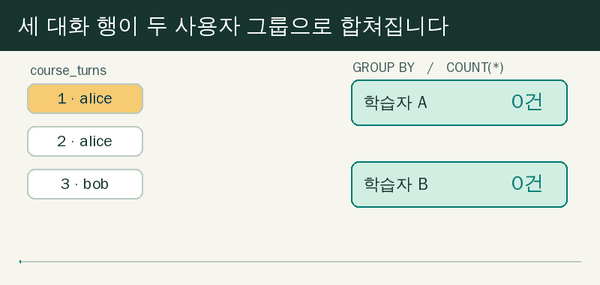

각 대화 행의 owner가 사용자 id와 일치하는 곳으로 이동합니다. COUNT(*)로 세면 학습자 A의 대화는 2건, B의 대화는 1건입니다.
<!-- /lesson-visual visual-join-count -->


### 셀 03 · JOIN과 GROUP BY 집계

JOIN으로 이름을 붙인 뒤 사용자별 행 수를 집계합니다.


In [3]:
sql = """SELECT u.display_name, COUNT(*) AS turn_count
FROM course_users AS u
JOIN course_turns AS t ON t.owner = u.id
GROUP BY u.id, u.display_name
ORDER BY u.id"""
print(db.execute(sql).fetchall())

[('학습자 A', 2), ('학습자 B', 1)]


학습자 A는 두 건, 학습자 B는 한 건입니다. 이 INNER JOIN은 질문이 하나도 없는 사용자는 세지 않습니다. 그 사용자까지 표시하려면 LEFT JOIN과 COUNT할 열을 함께 검토하세요.


## 선택 실습 · PostgreSQL에서 집계 실행

강사가 PostgreSQL의 53장 B1 테이블을 준비하고 psycopg가 있는 커널에 수업용 접속 정보(PGHOST·PGPORT·PGDATABASE·PGUSER·PGPASSWORD)와 HK_COURSE_USE_POSTGRES=1을 설정하면 아래 셀이 같은 SQL을 읽기 전용 트랜잭션에서 실행합니다. 접속 정보는 노트북에 입력할 필요가 없습니다.


### 셀 04 · 선택 실습 · PostgreSQL 집계

교실의 PostgreSQL 테이블을 연결했다면 방금 작성한 집계 쿼리를 그대로 보냅니다. 준비되지 않은 커널에서는 안내만 표시합니다.


In [4]:
from importlib.util import find_spec
import os
pg_ready = find_spec("psycopg") is not None and os.getenv("HK_COURSE_USE_POSTGRES") == "1"
if pg_ready:
    import psycopg
    with psycopg.connect(connect_timeout=3) as connection:
        connection.execute("SET TRANSACTION READ ONLY")
        print(connection.execute(sql).fetchall())
else:
    print("PostgreSQL 연결은 준비된 수업 커널에서 확인하세요.")

PostgreSQL 연결은 준비된 수업 커널에서 확인하세요.


실제 DB에 초기 자료만 있다면 같은 두 행을 볼 수 있습니다. 후속 실습으로 행이 늘어난 DB에서는 집계도 바뀝니다. 안내만 출력됐다면 SQLite에서의 SQL 실행과 PostgreSQL의 실제 접속을 구분해 기록하세요. 서버 실습 전에는 수업용 PostgreSQL에 예제 표와 행이 있는지, 커널에 psycopg와 연결 설정이 있는지 확인하세요. 준비한 환경에서 HK_COURSE_USE_POSTGRES=1을 설정한 뒤 출력된 이름별 개수를 SQLite 결과와 대조하세요.


## 돌아보기

필요한 행은 WHERE, 반환할 열은 SELECT, 표 간 연결 조건은 JOIN의 ON에 놓입니다. 동료에게 읽힐 결과에는 ID와 표시 이름 중 무엇이 필요한지 먼저 정해 보세요.

### 같은 세 행에서 결과를 좁히기

**질문 세 개**　alice의 두 질문과 bob의 한 질문이 있습니다.

```
id1 alice 언제 여나요?
id2 alice 주말 운영은요?
id3 bob 이용 절차는요?
```

**alice 행만 남기기**　owner 값이 같은 두 행을 남깁니다.

```
id1 alice 언제 여나요?
id2 alice 주말 운영은요?
```

**큰 id부터 놓기**　같은 두 행의 순서를 바꿉니다.

```
id2 alice 주말 운영은요?
id1 alice 언제 여나요?
```

**첫 한 행만 읽기**　정렬된 결과의 맨 앞 한 행을 반환합니다.

```
id2 alice 주말 운영은요?
```
